# River-1 quickstart

Simulate the weekly MMM dataset of PyMC-Marketing's
[MMM example](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_example.html) with its
adstock and saturation transformers, load River-1 from the Hub and decompose the sales: the model
sees the outcome of the first 80% of the weeks (context) and decomposes both the context and the
remaining 20% (query), with no model fit.

Requires `pip install 'pymc-mfm[hub,diagnostics,examples]'` and access to the private
`pymc-labs/mfm` repository (`hf auth login`).

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import torch
import xarray as xr
from pymc_marketing.mmm.transformers import geometric_adstock, logistic_saturation

from pymc_mfm import decompose, from_pretrained
from pymc_mfm.plotting.panels import COLORS

# 200 dpi, the resolution of PyMC-Marketing's notebooks (100 dpi, retina): sharper, larger figures.
plt.rcParams["figure.dpi"] = 200

## 1. Load River-1

The bundle (about 10 MB) is downloaded into a temporary folder at a pinned repository commit.

In [2]:
workspace = TemporaryDirectory(prefix="river-1-")
model = from_pretrained(
    "pymc-labs/mfm",
    profile="river-1",
    revision="970e6095f14824d7e25ecace7e20a47bebde35b8",
    cache_dir=Path(workspace.name) / "hub",
)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
model.config

2,443,583 parameters


ModelConfig(d_model=128, n_layers=4, n_heads=8, d_ff=512, flow_hidden=256, n_controls=10, n_demand=1)

## 2. Generate the data

The PyMC-Marketing data-generating process: two channels with geometric adstock (an eight-week
window, lags 0–7) and logistic saturation, both from `pymc_marketing.mmm.transformers`, a trend, yearly
seasonality, two one-week events, an intercept and Gaussian noise, in sales units (thousands). The
series has 208 weeks, the history length River-1 was trained on.

In [3]:
seed = sum(map(ord, "mmm"))
rng = np.random.default_rng(seed=seed)
N_WEEKS = 208
dates = np.datetime64("2018-04-02") + 7 * np.arange(N_WEEKS)
dayofyear = (dates - dates.astype("datetime64[Y]")).astype(int) + 1

x1 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x1 = np.where(x1 > 0.9, x1, x1 / 2)
x2 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x2 = np.where(x2 > 0.8, x2, 0.0)

In [4]:
SCALE = 1_000
ADSTOCK_L_MAX = 8
media_parameters = {
    "x1": {"alpha": 0.4, "lam": 4.0, "beta": 3.0},
    "x2": {"alpha": 0.2, "lam": 3.0, "beta": 2.0},
}
x1_adstock = geometric_adstock(
    xr.DataArray(x1, dims="week"),
    alpha=media_parameters["x1"]["alpha"],
    l_max=ADSTOCK_L_MAX,
    normalize=True,
    dim="week",
)
x2_adstock = geometric_adstock(
    xr.DataArray(x2, dims="week"),
    alpha=media_parameters["x2"]["alpha"],
    l_max=ADSTOCK_L_MAX,
    normalize=True,
    dim="week",
)
media = np.column_stack(
    [
        media_parameters["x1"]["beta"]
        * logistic_saturation(x1_adstock, lam=media_parameters["x1"]["lam"]).eval(),
        media_parameters["x2"]["beta"]
        * logistic_saturation(x2_adstock, lam=media_parameters["x2"]["lam"]).eval(),
    ]
)
trend = (np.linspace(start=0.0, stop=50, num=N_WEEKS) + 10) ** (1 / 4) - 1
seasonality = 0.5 * (
    -np.sin(2 * 2 * np.pi * dayofyear / 365.5) + np.cos(1 * 2 * np.pi * dayofyear / 365.5)
)
events = np.column_stack(
    [dates == np.datetime64("2019-05-13"), dates == np.datetime64("2020-09-14")]
).astype(float)
epsilon = rng.normal(loc=0.0, scale=0.25, size=N_WEEKS)

# True contributions in sales units.
baseline = SCALE * (2.0 + trend + seasonality)
channel_truth = SCALE * media
event_truth = SCALE * events * [1.5, 2.5]
y = baseline + channel_truth.sum(axis=1) + event_truth.sum(axis=1) + SCALE * epsilon

## 3. Split context and query

The model receives spend and controls for every week, but sales only for the context weeks.

166 context weeks, 42 query weeks


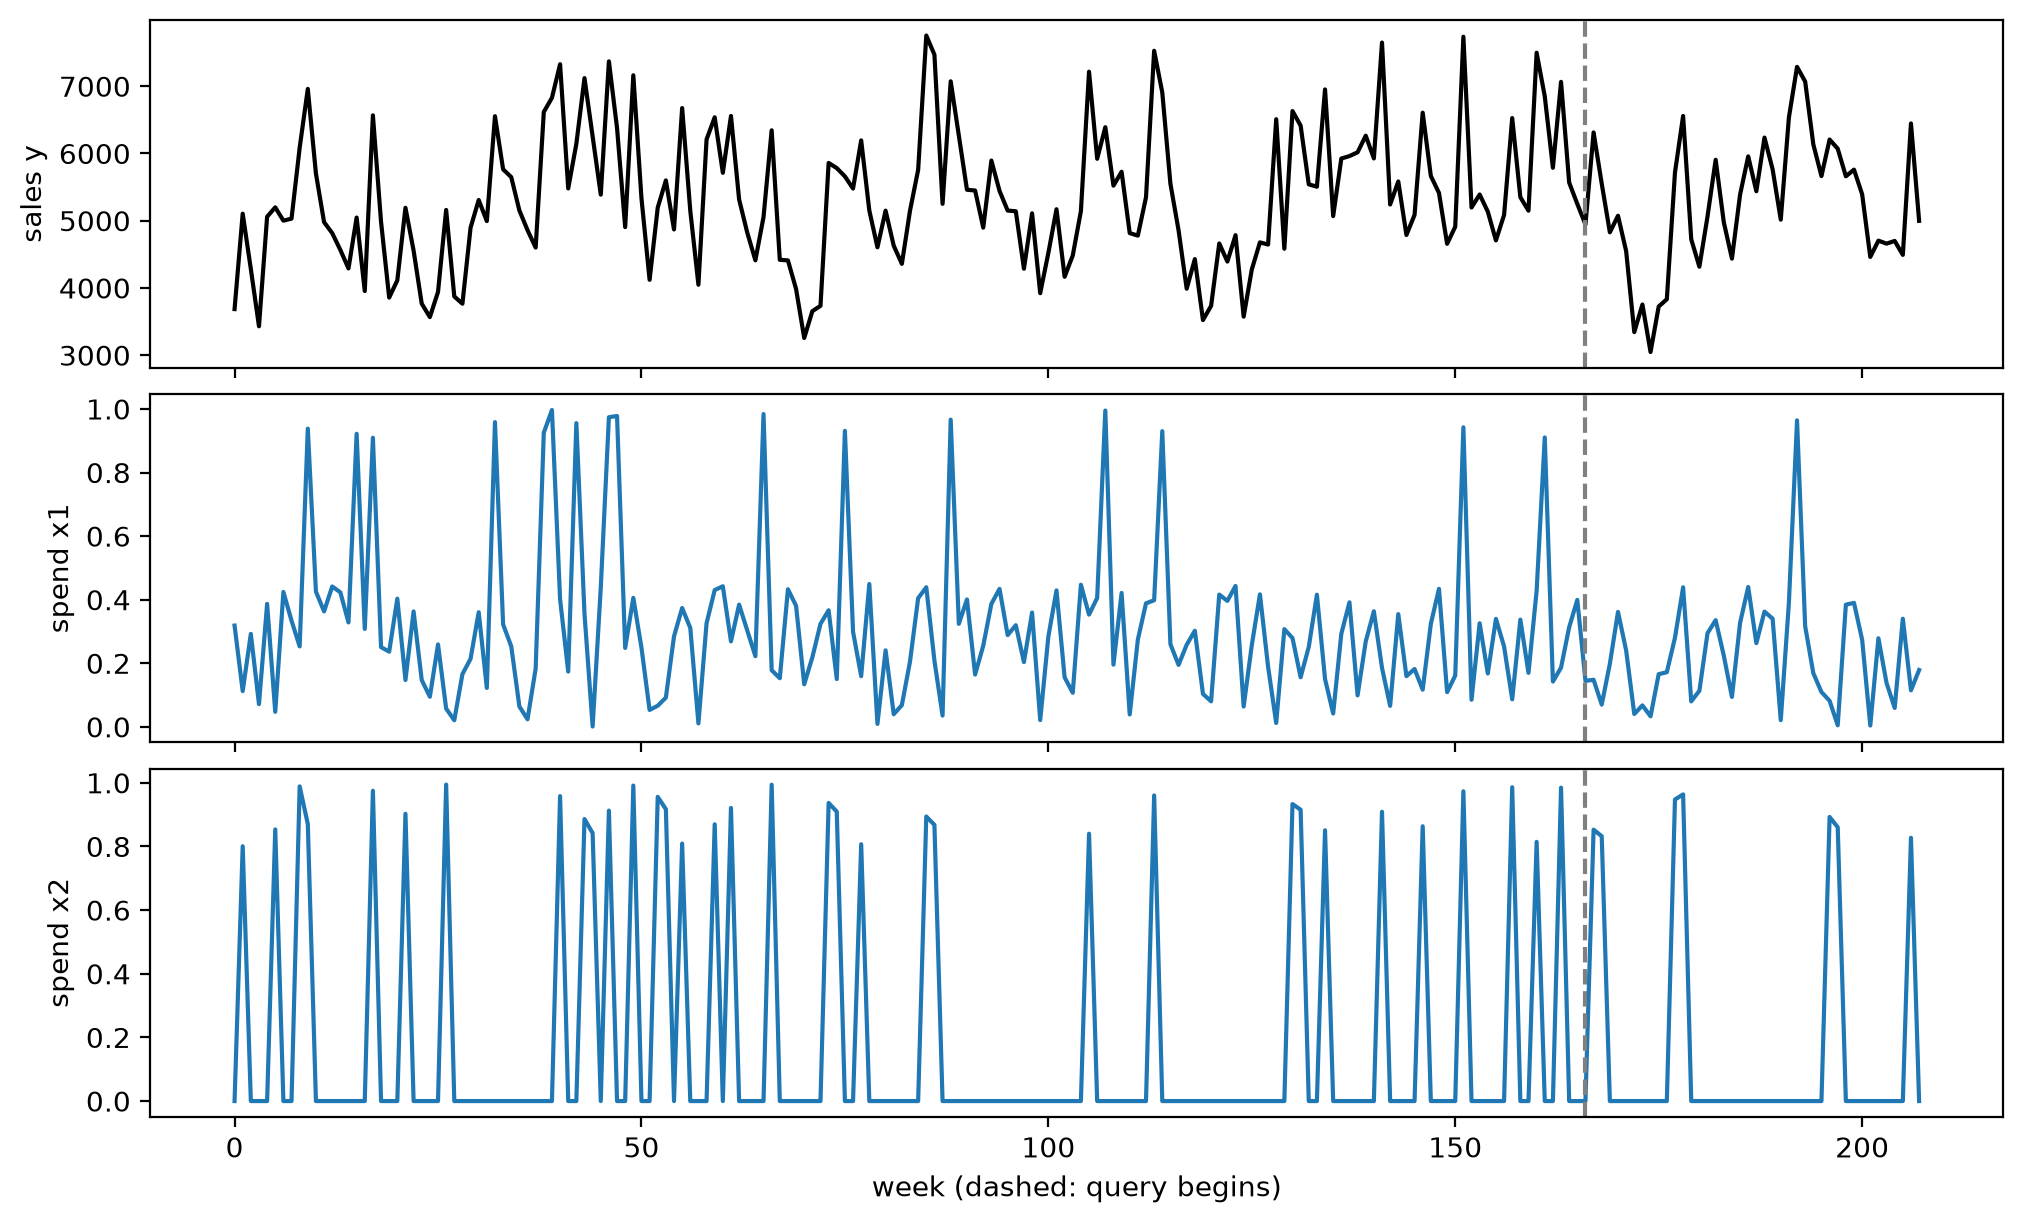

In [5]:
CONTEXT = int(0.8 * N_WEEKS)
print(f"{CONTEXT} context weeks, {N_WEEKS - CONTEXT} query weeks")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
for ax, values, label in zip(axes, (y, x1, x2), ("sales y", "spend x1", "spend x2"), strict=True):
    ax.plot(values, color="black" if label == "sales y" else None)
    ax.axvline(CONTEXT, color="0.5", linestyle="--")
    ax.set_ylabel(label)
axes[-1].set_xlabel("week (dashed: query begins)");

## 4. Decompose

River-1 has 10 control slots: the two events fill the first two and the mask marks the rest as
unused. Intercept, trend and seasonality belong to the model's baseline. Context and query are
decomposed separately, each with 1,000 posterior draws instead of the default 32.

In [6]:
controls = np.zeros((N_WEEKS, model.config.n_controls))
controls[:, :2] = events
observations = {
    "spend": np.column_stack([x1, x2]),
    "controls": controls,
    "context_outcome": y[:CONTEXT],
    "control_mask": [1, 1] + [0] * (model.config.n_controls - 2),
}
names = {
    "channel_names": ("x1", "x2"),
    "control_names": ("event_1", "event_2", *(f"unused_{i}" for i in range(2, 10))),
}
torch.manual_seed(0)
context = decompose(model, observations, n_samples=1_000, window="context", **names)
query = decompose(model, observations, n_samples=1_000, window="query", **names)
query.components.shape  # [draw, week, component]

(1000, 42, 17)

## 5. Contributions

Window totals against the truth, with the x1 share of media contribution (0.81 over the
PyMC-Marketing example's 179 weeks):

In [7]:
def compare(result, weeks):
    truth = {
        "baseline": baseline[weeks],
        "channel:x1": channel_truth[weeks, 0],
        "channel:x2": channel_truth[weeks, 1],
    }
    print(f"{result.window} window ({result.components.shape[1]} weeks)")
    means = {}
    for name, values in truth.items():
        draws = result.components[:, :, result.component_names.index(name)].sum(axis=1)
        low, high = np.quantile(draws, [0.05, 0.95])
        means[name] = draws.mean()
        print(
            f"  {name:<11} truth {values.sum():>9,.0f}  "
            f"posterior mean {means[name]:>9,.0f}  90% [{low:,.0f}, {high:,.0f}]"
        )
    true_share = truth["channel:x1"].sum() / (truth["channel:x1"] + truth["channel:x2"]).sum()
    share = means["channel:x1"] / (means["channel:x1"] + means["channel:x2"])
    print(f"  x1 share    truth {true_share:.2f}  posterior mean {share:.2f}")


compare(context, slice(None, CONTEXT))
compare(query, slice(CONTEXT, None))

context window (166 weeks)
  baseline    truth   549,086  posterior mean   491,523  90% [373,507, 605,464]
  channel:x1  truth   261,603  posterior mean   205,599  90% [124,996, 280,093]
  channel:x2  truth    70,252  posterior mean    62,515  90% [52,521, 73,018]
  x1 share    truth 0.79  posterior mean 0.77
query window (42 weeks)
  baseline    truth   155,333  posterior mean   150,104  90% [97,210, 202,096]
  channel:x1  truth    51,407  posterior mean    33,646  90% [21,417, 47,060]
  channel:x2  truth    13,690  posterior mean    12,833  90% [10,375, 15,513]
  x1 share    truth 0.79  posterior mean 0.72


## 6. Sales in the query weeks

The sum of the components is the model's sales in weeks whose outcome it never saw; it excludes
observation noise.

mean absolute error 760
held-out weeks inside the 90% interval: 90%


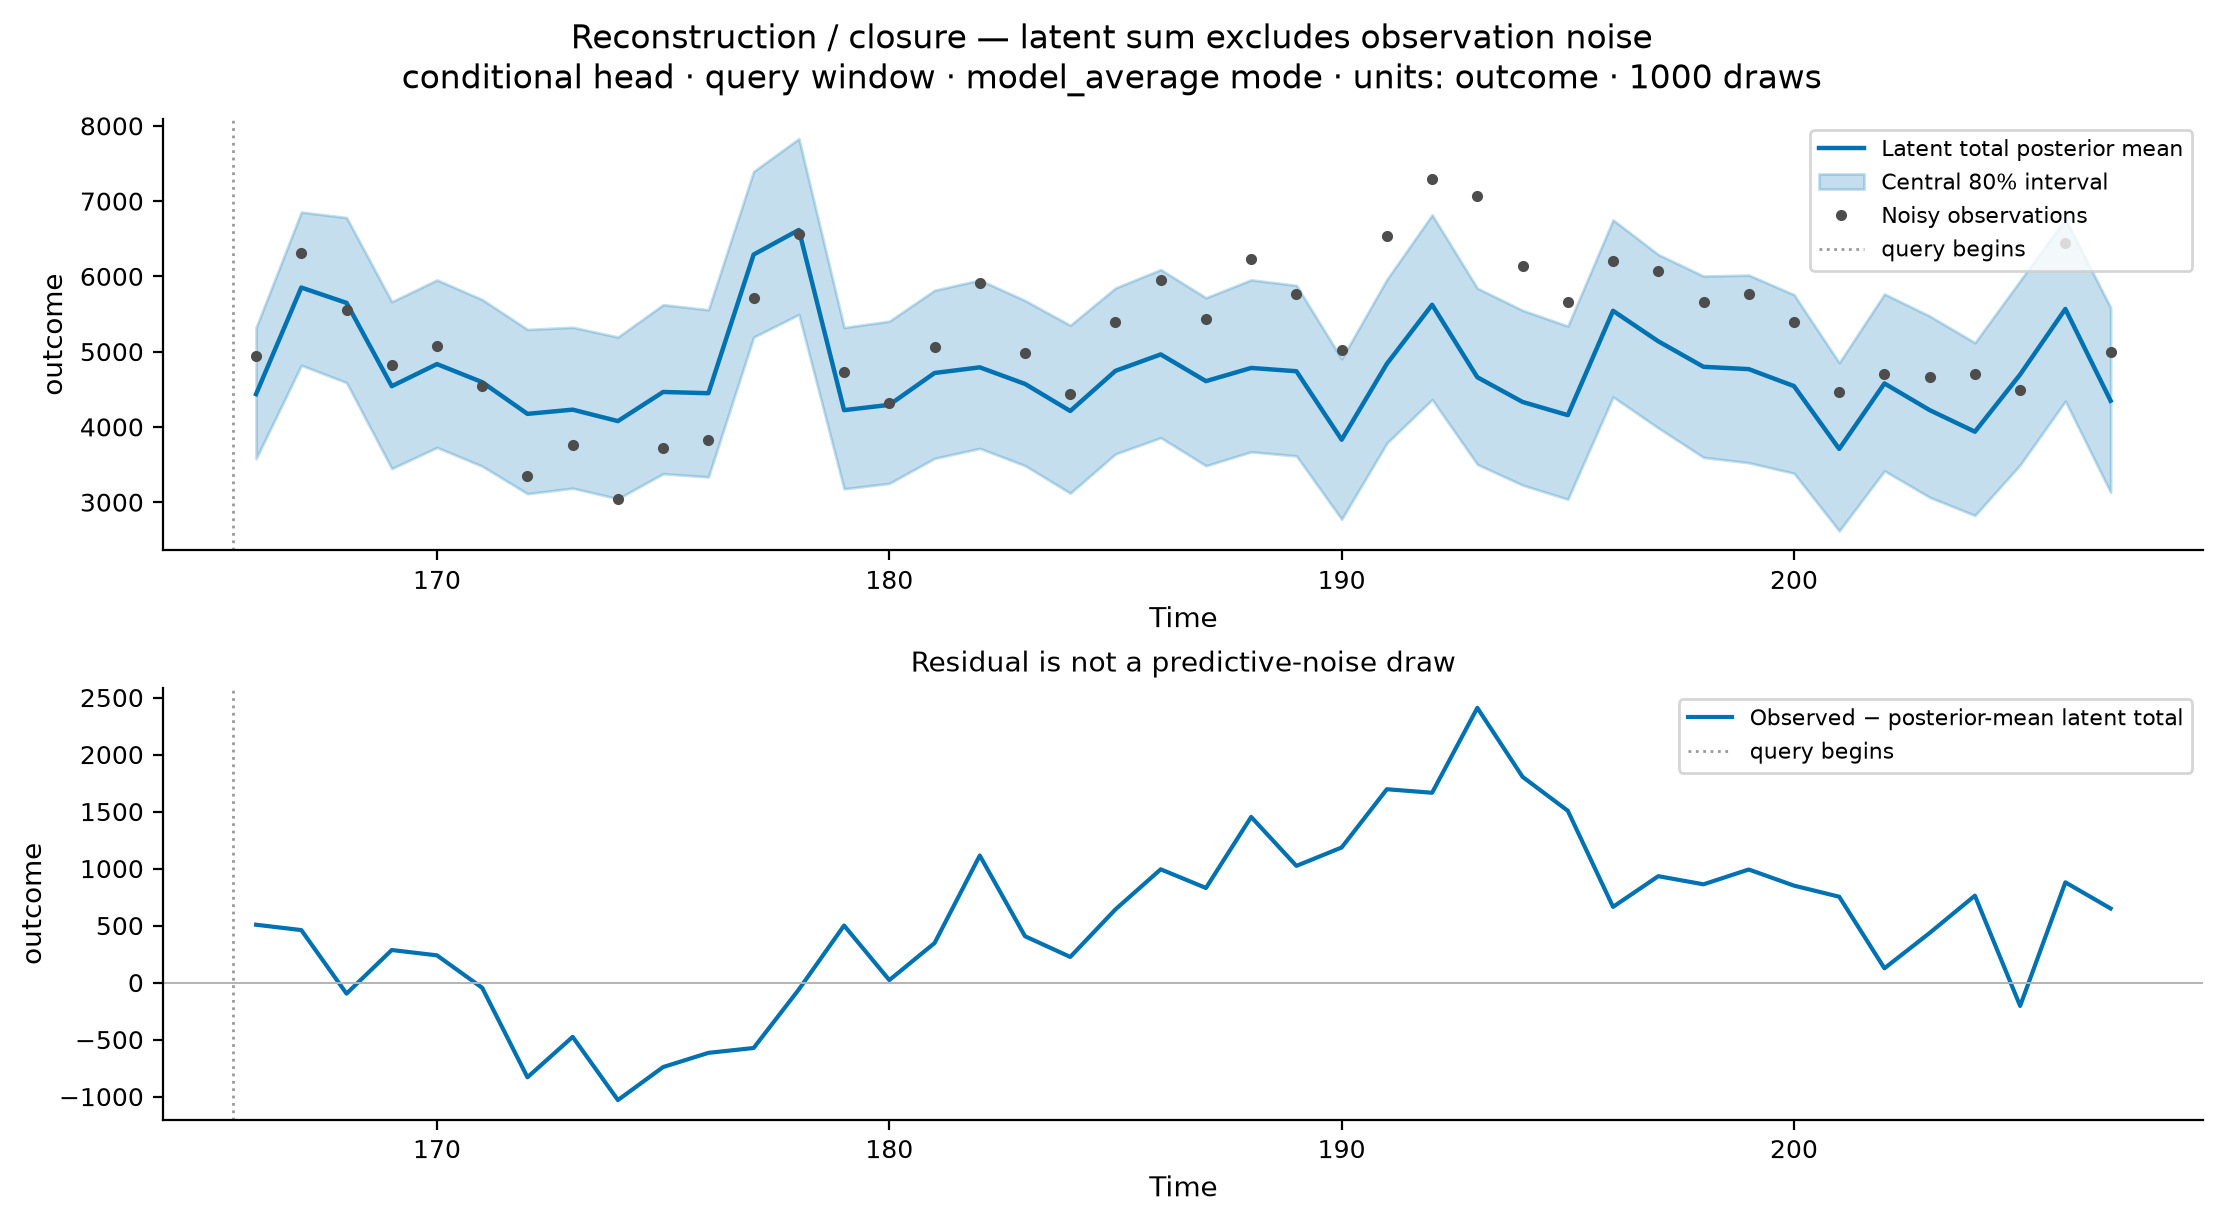

In [8]:
sales = query.components.sum(axis=2)
low, high = np.quantile(sales, [0.05, 0.95], axis=0)
held_out = y[CONTEXT:]
print(f"mean absolute error {np.abs(sales.mean(axis=0) - held_out).mean():,.0f}")
print(
    f"held-out weeks inside the 90% interval: {np.mean((low <= held_out) & (held_out <= high)):.0%}"
)
query.plot.reconstruction(observed=held_out)

## 7. Recovery

Each channel's and control's contribution week by week: the posterior mean with its central 80%
interval against the true contribution (dashed). Then the posterior distribution of each effect
against its true value (dashed): a channel's total over the window and an event's contribution in
its week. Both events fall in the context weeks, so the query shows the channels only; the mask
leaves the unused control slots out.

In [9]:
# True contributions in the result's component order (baseline, channels, controls, latent,
# indirect); the unused control slots, latent and indirect components are zero.
truth = np.column_stack(
    [baseline, channel_truth, event_truth, np.zeros((N_WEEKS, len(query.component_names) - 5))]
)
context_diagnostics = context.diagnostics(truth=truth[:CONTEXT])
query_diagnostics = query.diagnostics(truth=truth[CONTEXT:])


def plot_effect_posteriors(result, effects):
    """Posterior draws of each effect, summed over its weeks, against its true value."""
    rows = len(effects) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(12, 3.5 * rows), squeeze=False, layout="constrained")
    for ax, (name, weeks) in zip(axes.flat, effects.items(), strict=True):
        index = result.component_names.index(name)
        ax.hist(
            result.components[:, np.isin(result.time, weeks), index].sum(axis=1),
            bins=40,
            color=COLORS[name.split(":")[0]],
            alpha=0.6,
            label="Posterior draws",
        )
        ax.axvline(truth[weeks, index].sum(), color="black", linestyle="--", label="Truth")
        ax.spines[["top", "right"]].set_visible(False)
        span = f"in week {weeks[0]}" if len(weeks) == 1 else f"over weeks {weeks[0]}–{weeks[-1]}"
        ax.set(title=name, xlabel=f"Contribution {span} (sales)", ylabel="Draws")
    axes[0, 0].legend()
    fig.suptitle(f"Effect posteriors — {result.window} window, {len(result.components)} draws")

### Context

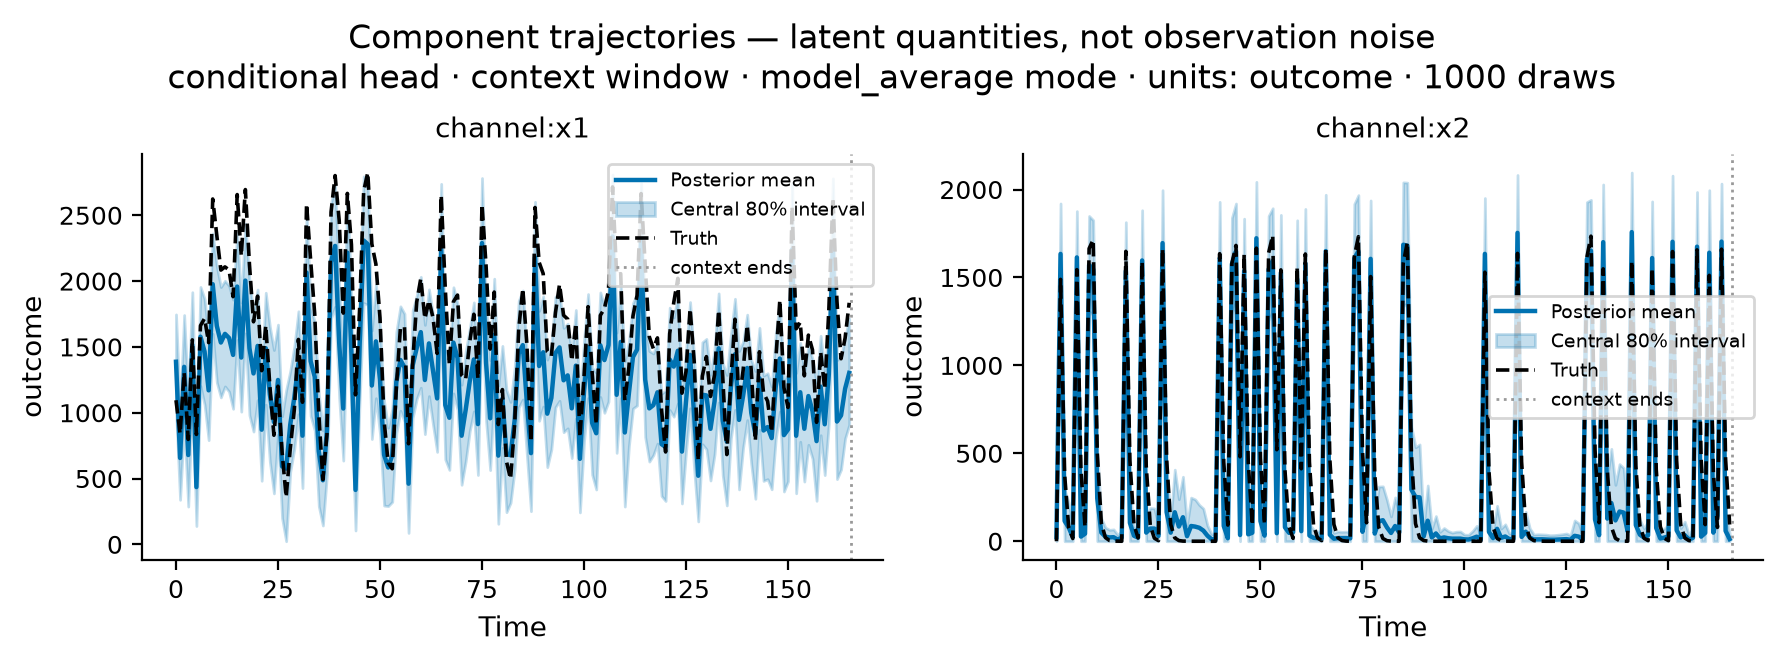

In [10]:
context_diagnostics.plot.channels()

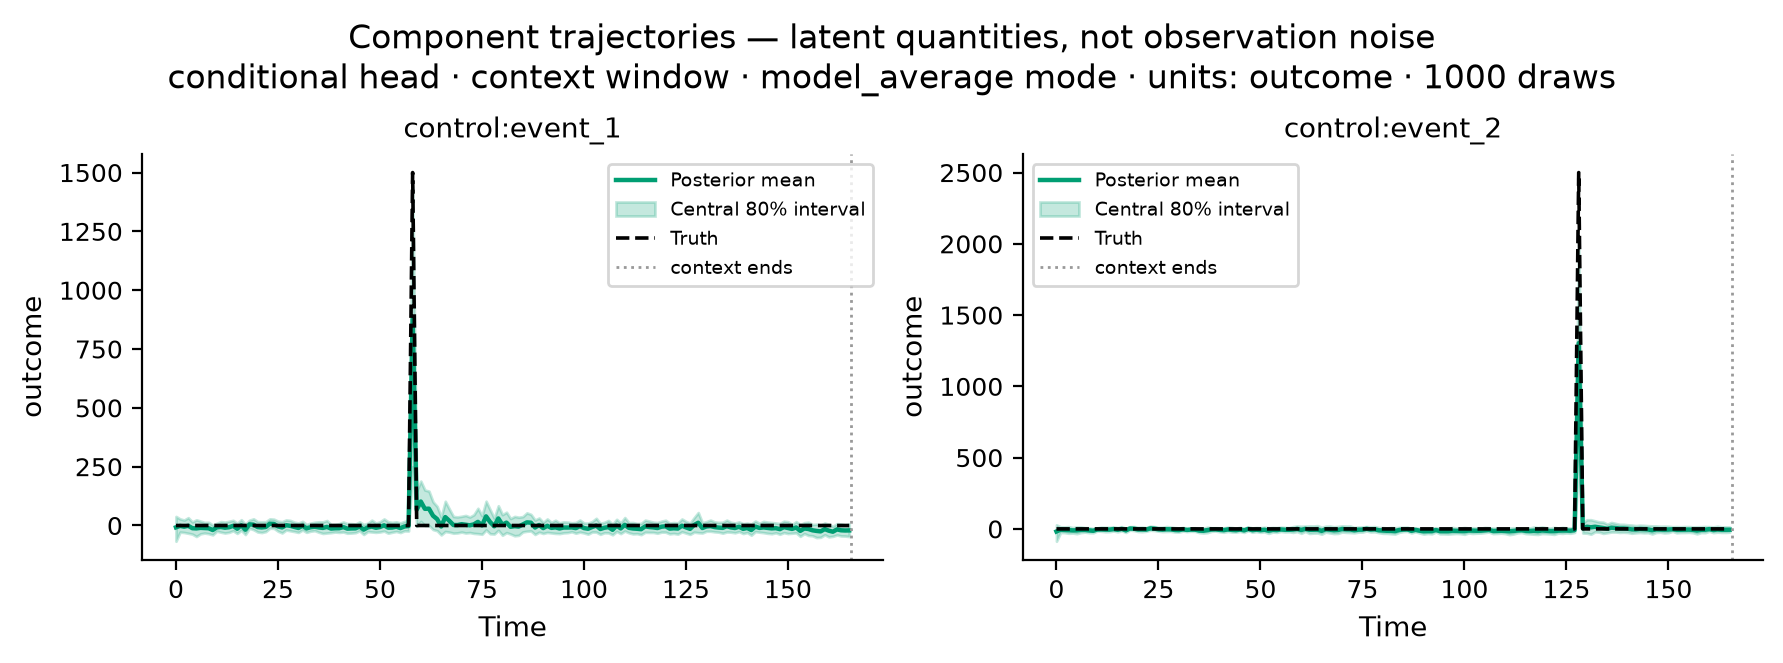

In [11]:
context_diagnostics.plot.controls()

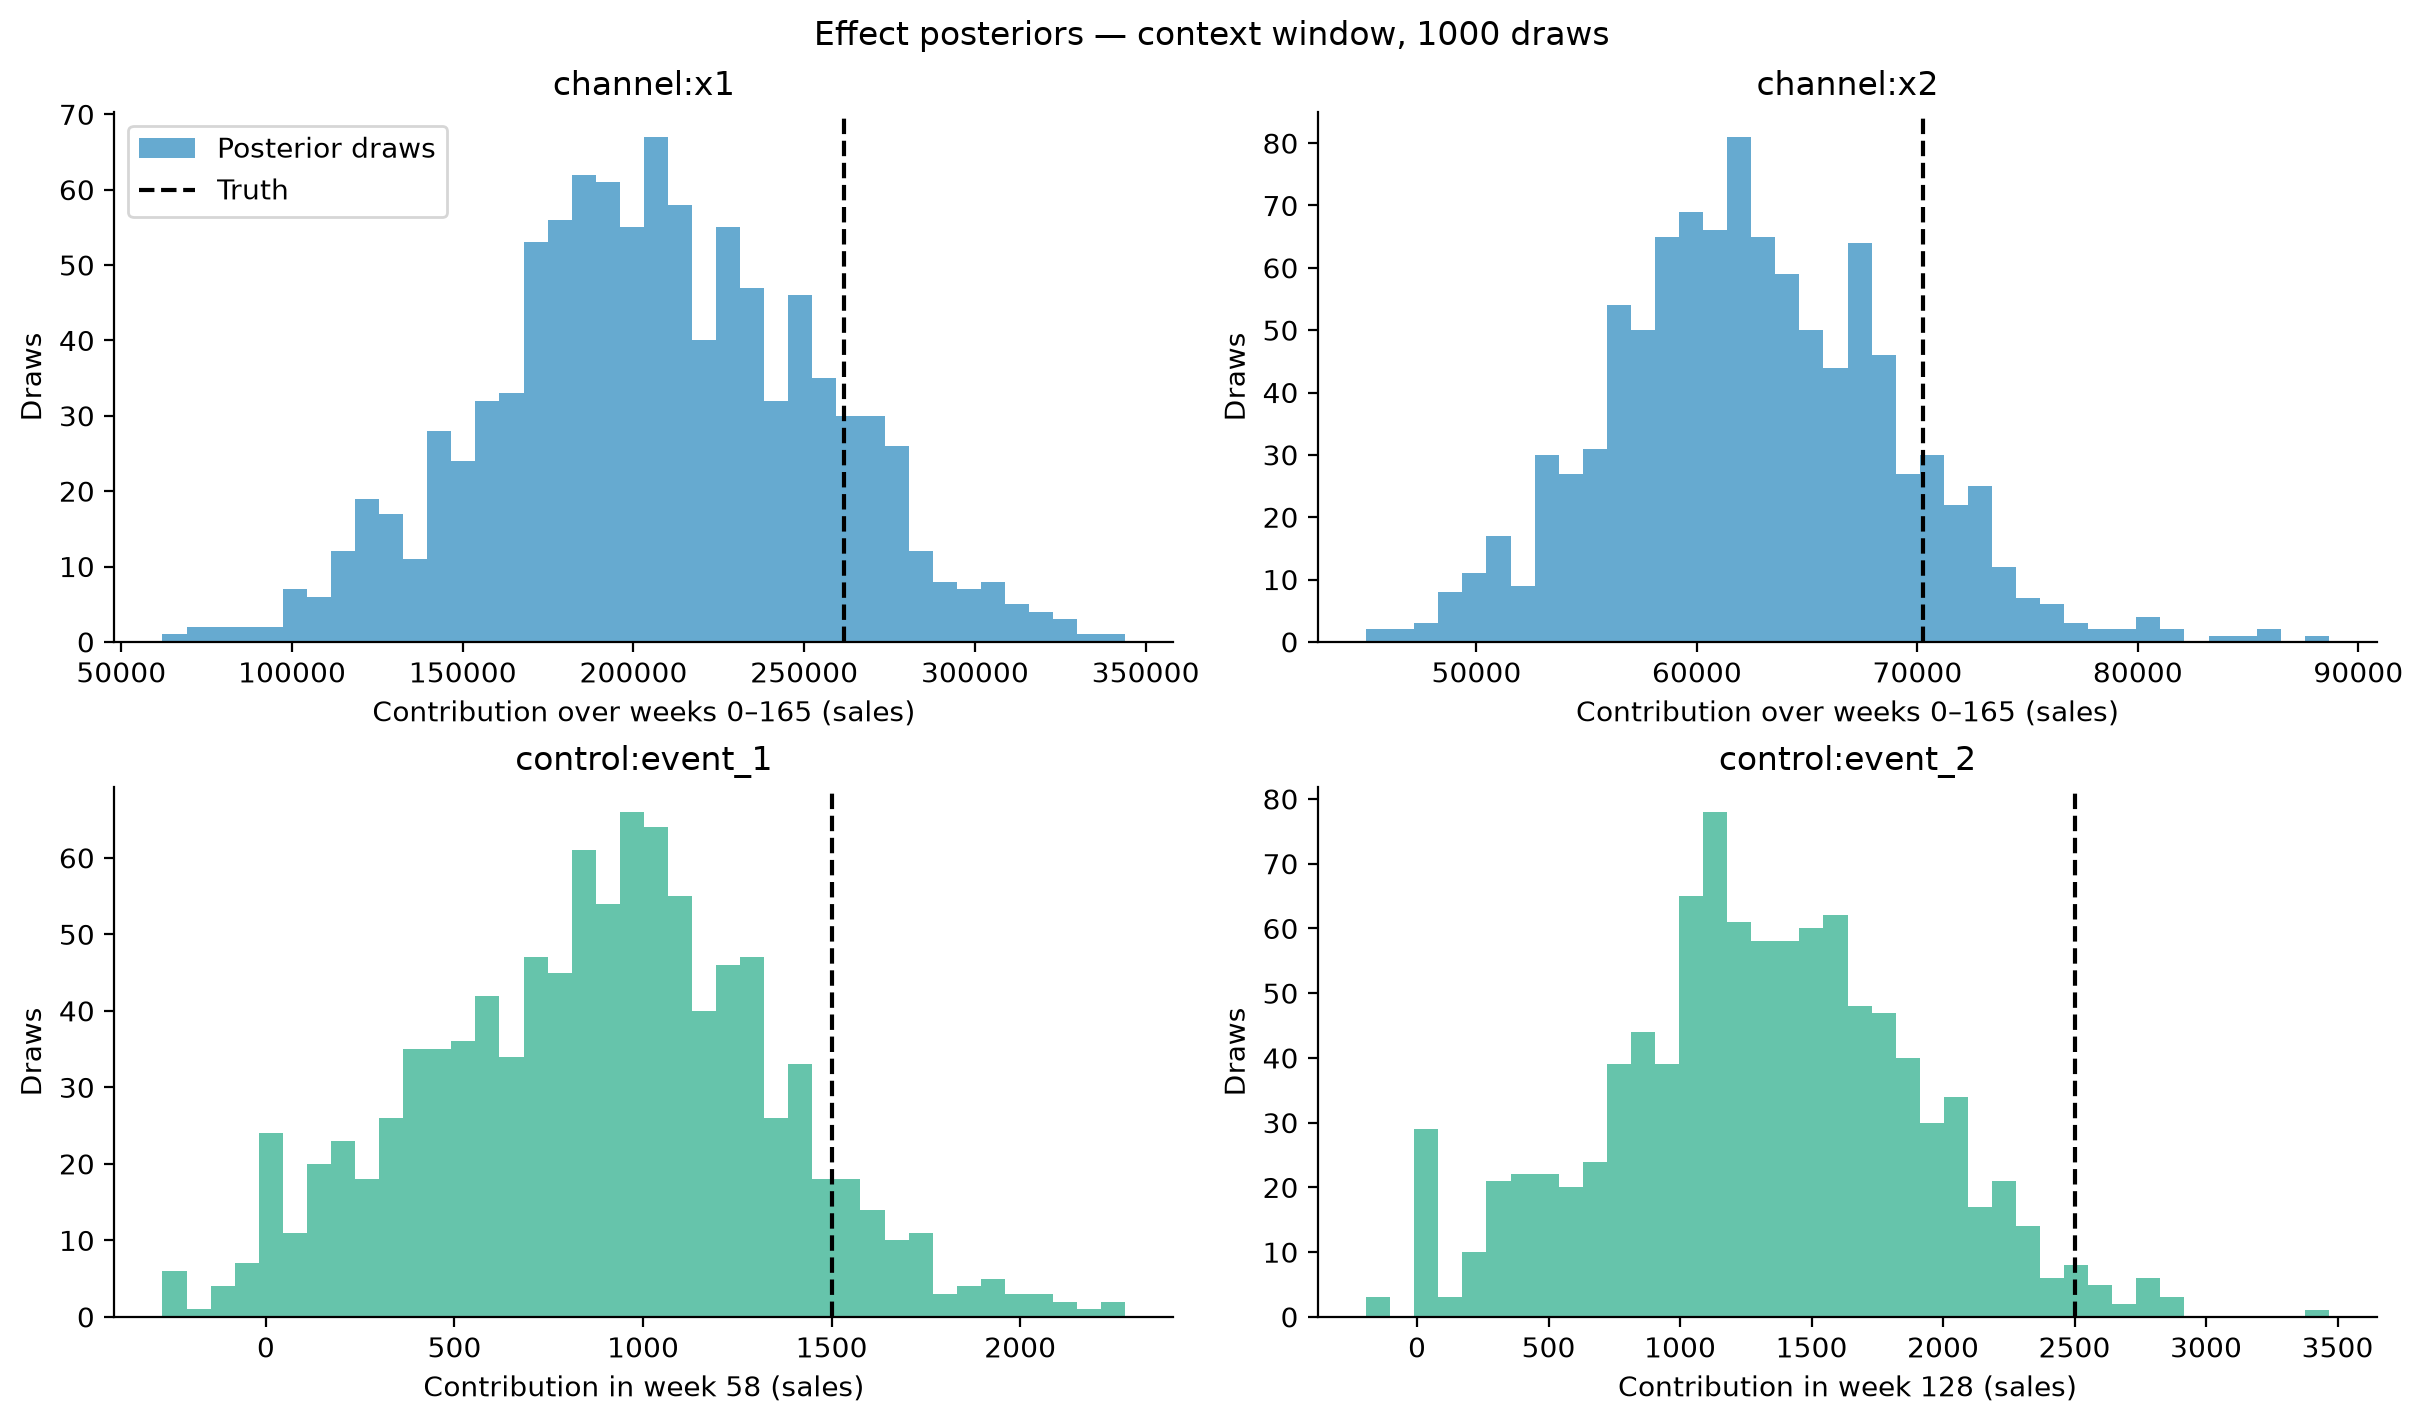

In [12]:
plot_effect_posteriors(
    context,
    {
        "channel:x1": context.time,
        "channel:x2": context.time,
        "control:event_1": np.flatnonzero(events[:, 0]),
        "control:event_2": np.flatnonzero(events[:, 1]),
    },
)

### Query

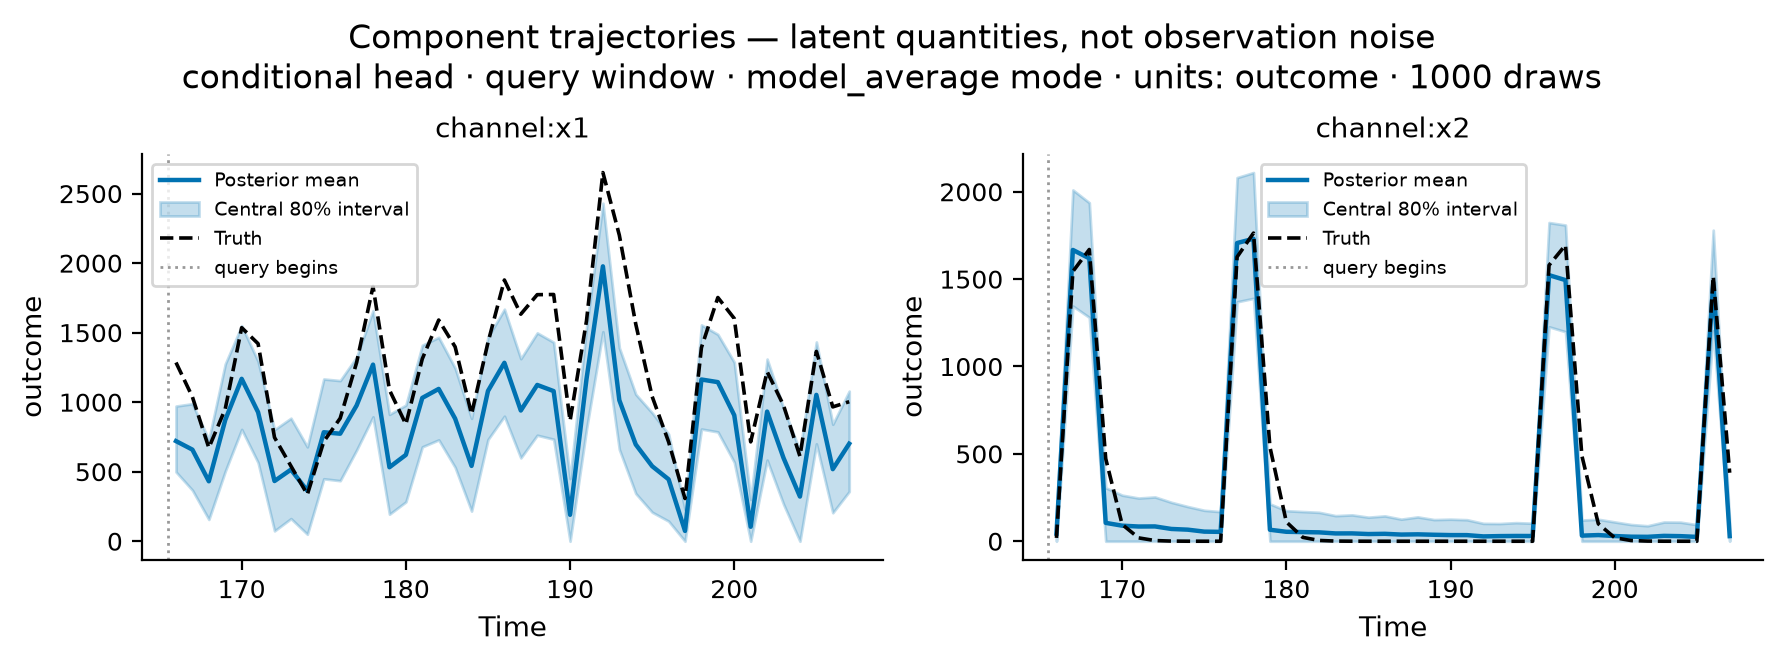

In [13]:
query_diagnostics.plot.channels()

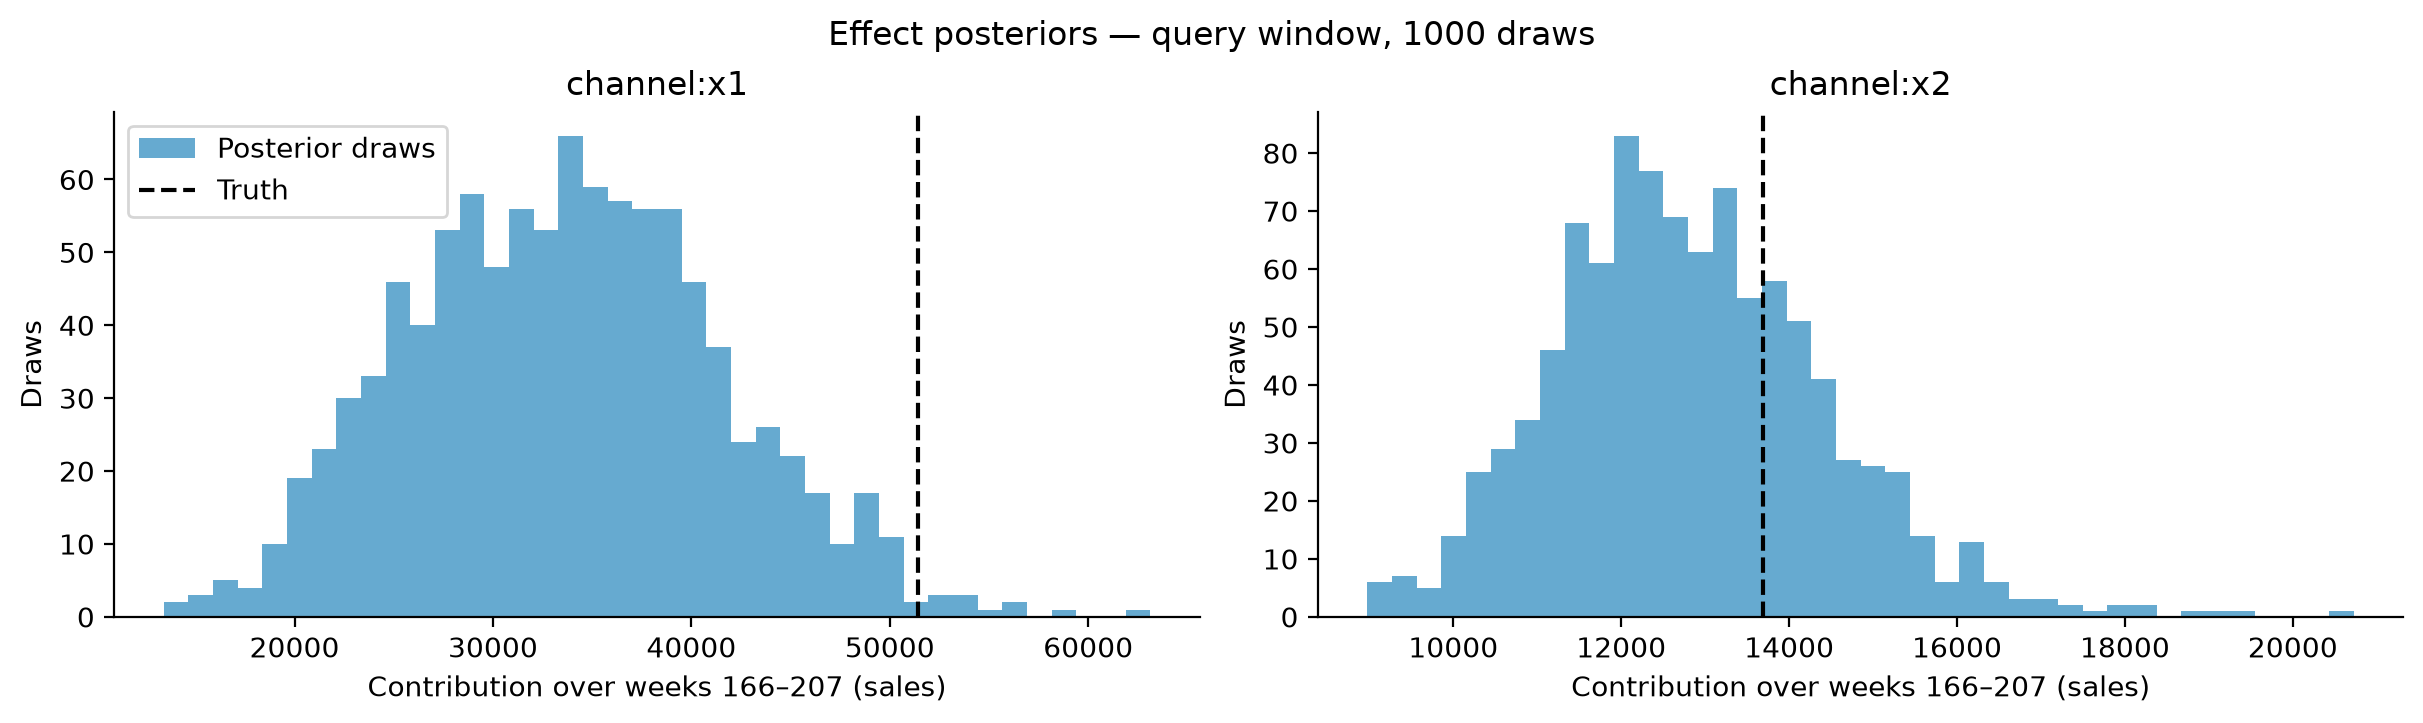

In [14]:
plot_effect_posteriors(query, {"channel:x1": query.time, "channel:x2": query.time})

## 8. Context raw spend: River-1 versus simulated truth

One panel per channel, using **context weeks only**. Both scatter series have the same raw
weekly spend on the x-axis and channel contribution in sales units on the y-axis:

- Black crosses: the simulated true contribution after adstock, saturation and channel scaling.
- Blue circles: River-1's posterior mean contribution for that same channel and week.

There is no adstocked-spend x-axis and no query series. Because contributions depend on past
spend as well as current spend, points need not lie on a single raw-spend response curve.

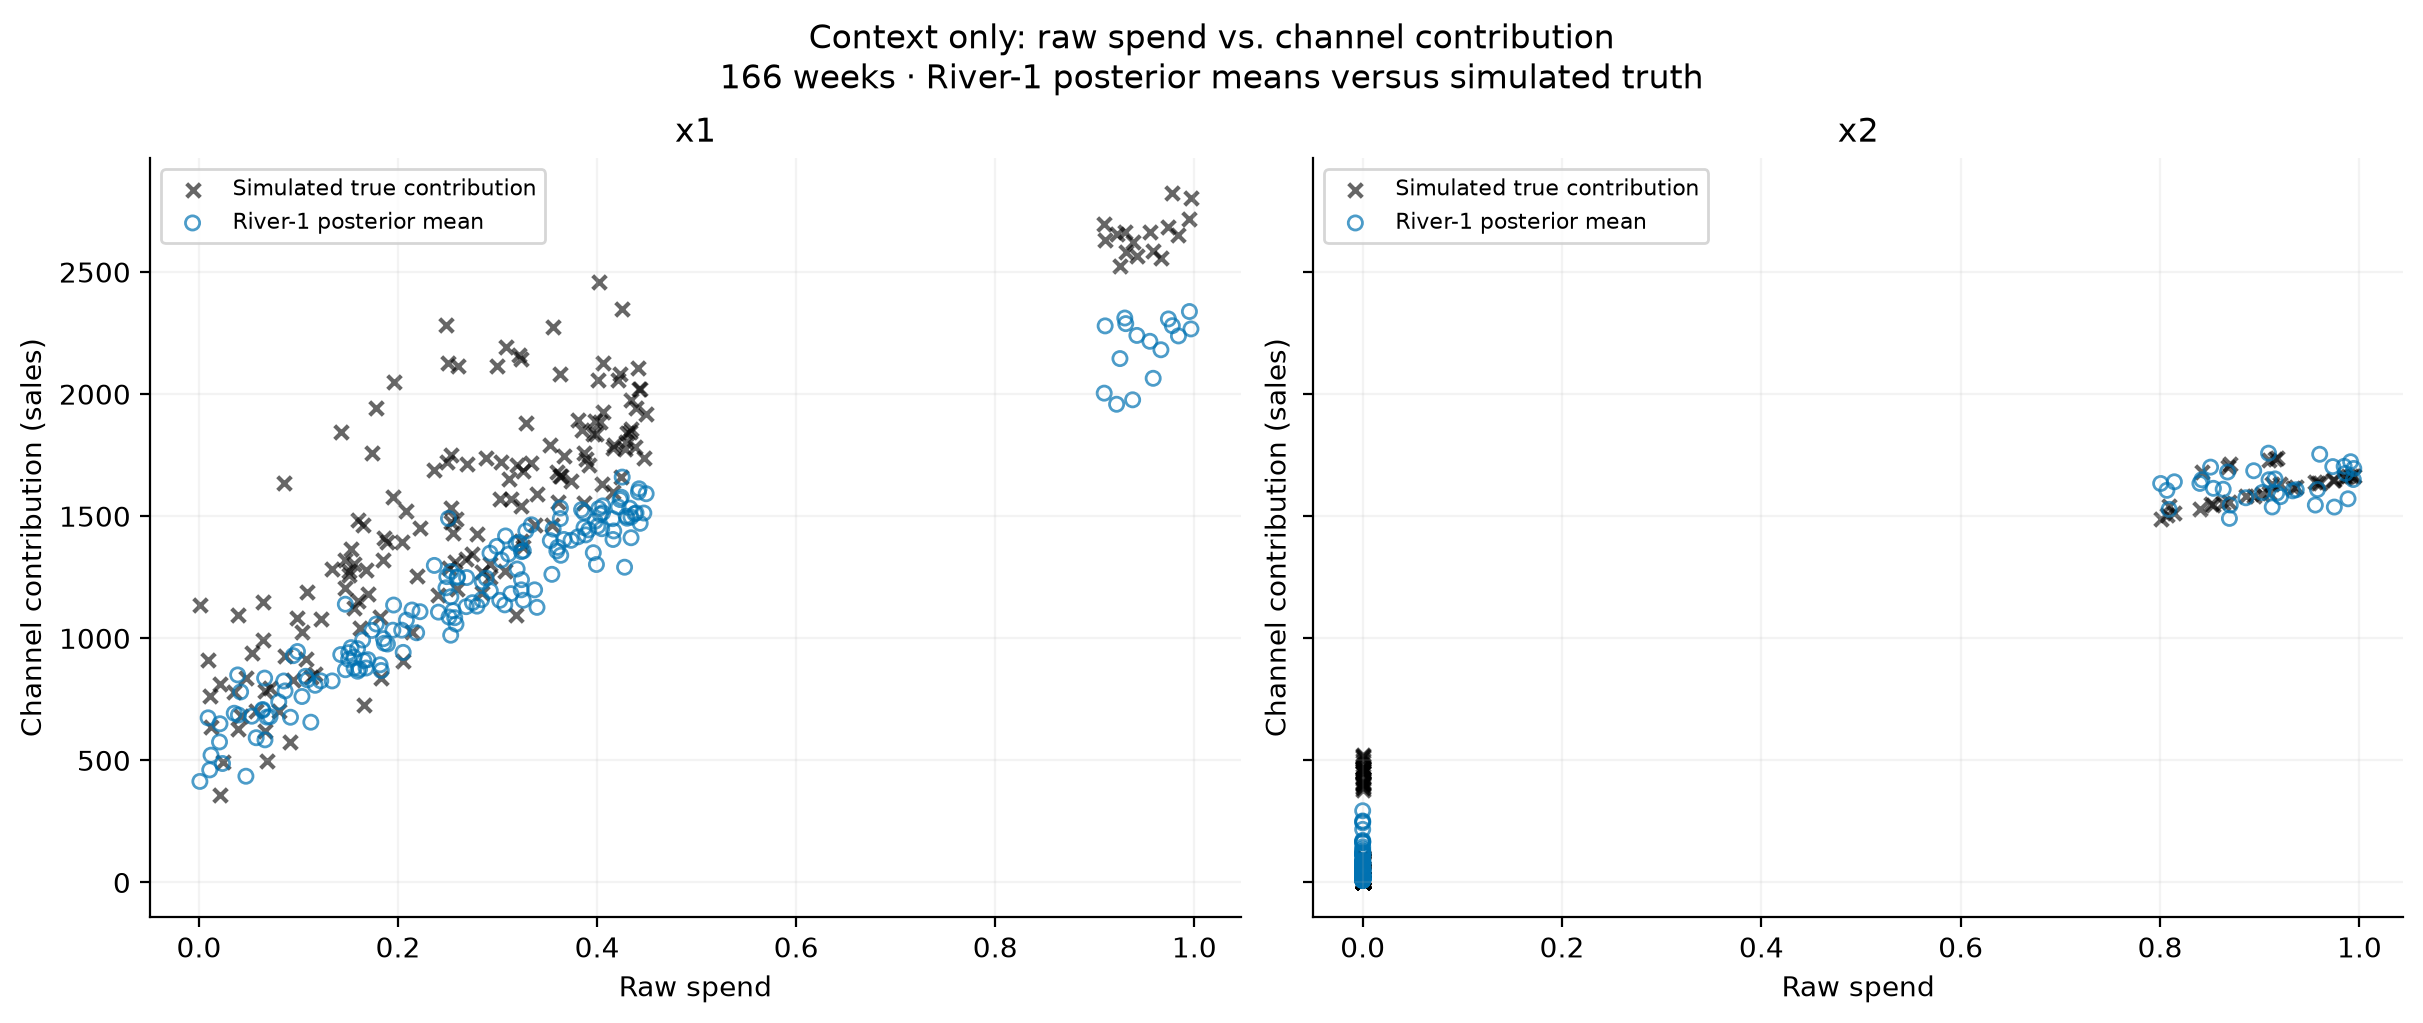

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
context_means = context.components.mean(axis=0)
for channel_index, (ax, name) in enumerate(zip(axes, names["channel_names"], strict=True)):
    raw_spend = observations["spend"][context.time, channel_index]
    component_index = context.component_names.index(f"channel:{name}")
    ax.scatter(
        raw_spend,
        channel_truth[context.time, channel_index],
        s=24,
        marker="x",
        color="black",
        alpha=0.6,
        label="Simulated true contribution",
    )
    ax.scatter(
        raw_spend,
        context_means[:, component_index],
        s=26,
        marker="o",
        facecolors="none",
        edgecolors=COLORS["channel"],
        alpha=0.7,
        label="River-1 posterior mean",
    )
    ax.set(title=name, xlabel="Raw spend", ylabel="Channel contribution (sales)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle(
    f"Context only: raw spend vs. channel contribution\n"
    f"{len(context.time)} weeks · River-1 posterior means versus simulated truth"
);

## 9. Sweep 0–200% of actual spend

For each channel separately, multiply its **actual spend path in the first eight query weeks**
by 0%, 5%, ..., 200%. The eight-week window includes spend for both channels; the first query
week alone has zero x2 spend. Multiplication preserves the weekly pattern, including zero-spend
weeks. Keep the 166 observed context weeks, other channel and controls unchanged.

Each percentage is a **separate scenario**, not a percentage assigned to successive weeks.
Run fresh inference over the same eight-week horizon, including a new 100% reference; do not
slice the earlier 42-week query decomposition. Sum the eight weekly channel contributions
**within each draw**, then calculate the posterior mean and central 90% interval across draws.
The calculation and plot are separate cells so the figure can be restyled without resampling.

Overlay the generator's true **adstock → logistic saturation → channel scaling** at the same
spend percentages and in the same eight-week total-sales units. Preserve the historical spend
before applying adstock, not just the eight query weeks. Small black dots are generator-computed
scenario truth; the orange star at 100% is the original dataset's actual eight-week channel total.
The star explicitly marks the unchanged observed spend path; other percentages are simulated
scenarios. Individual weekly points cannot be overlaid on this aggregate plot without mixing
units and historical conditions. These true contributions are available because this example
is simulated; they are not observed sales or parameters estimated by River-1.

These are conditional channel-contribution curves, not identified causal lift, fitted saturation
functions or steady-state responses. Graphs are model-averaged separately for each scenario.
Intervals are pointwise approximate posterior intervals, not simultaneous curve bands or
observation-noise prediction intervals; draws are not paired across spend levels. Zero new spend
does not erase historical spend, so its contribution need not be zero. Even proportional scenarios,
especially at 200%, can lie outside the model's well-supported input patterns.

In [16]:
SWEEP_WEEKS = 8
SWEEP_SAMPLES = 1_000
spend_multipliers = np.linspace(0.0, 2.0, 41)
sweep_stop = CONTEXT + SWEEP_WEEKS
sweep_window = slice(CONTEXT, sweep_stop)
sweep_observations = {
    **observations,
    "spend": observations["spend"][:sweep_stop].copy(),
    "controls": observations["controls"][:sweep_stop],
}
actual_spend_totals = sweep_observations["spend"][sweep_window].sum(axis=0)

torch.manual_seed(0)
# Share one fresh, unchanged-input reference between the two channel sweeps.
actual_sweep = decompose(
    model, sweep_observations, n_samples=SWEEP_SAMPLES, mode="model_average", **names
)
sweep_draws = {}
for channel_index, name in enumerate(names["channel_names"]):
    component_index = actual_sweep.component_names.index(f"channel:{name}")
    totals = []
    for multiplier in spend_multipliers:
        if multiplier == 1.0:
            result = actual_sweep
        else:
            scenario_spend = sweep_observations["spend"].copy()
            scenario_spend[sweep_window, channel_index] *= multiplier
            result = decompose(
                model,
                {**sweep_observations, "spend": scenario_spend},
                n_samples=SWEEP_SAMPLES,
                mode="model_average",
                **names,
            )
        totals.append(result.components[:, :, component_index].sum(axis=1))
    sweep_draws[name] = np.stack(totals)  # [spend level, draw], in sales units
    print(
        f"{name}: {len(spend_multipliers)} levels, {SWEEP_SAMPLES:,} draws per level; "
        f"actual eight-week spend = {actual_spend_totals[channel_index]:.3f} input units"
    )

x1: 41 levels, 1,000 draws per level; actual eight-week spend = 1.270 input units


x2: 41 levels, 1,000 draws per level; actual eight-week spend = 1.685 input units


In [17]:
sweep_truth = {}
for channel_index, name in enumerate(names["channel_names"]):
    parameters = media_parameters[name]
    # One row per scenario, including the identical real history before the query.
    scenario_paths = np.tile(
        sweep_observations["spend"][:, channel_index], (len(spend_multipliers), 1)
    )
    scenario_paths[:, sweep_window] *= spend_multipliers[:, None]
    adstocked_paths = geometric_adstock(
        xr.DataArray(scenario_paths, dims=("spend_level", "week")),
        alpha=parameters["alpha"],
        l_max=ADSTOCK_L_MAX,
        normalize=True,
        dim="week",
    )
    transformed_paths = (
        parameters["beta"] * logistic_saturation(adstocked_paths, lam=parameters["lam"]).eval()
    )
    sweep_truth[name] = (SCALE * transformed_paths)[:, sweep_window].sum(axis=1)

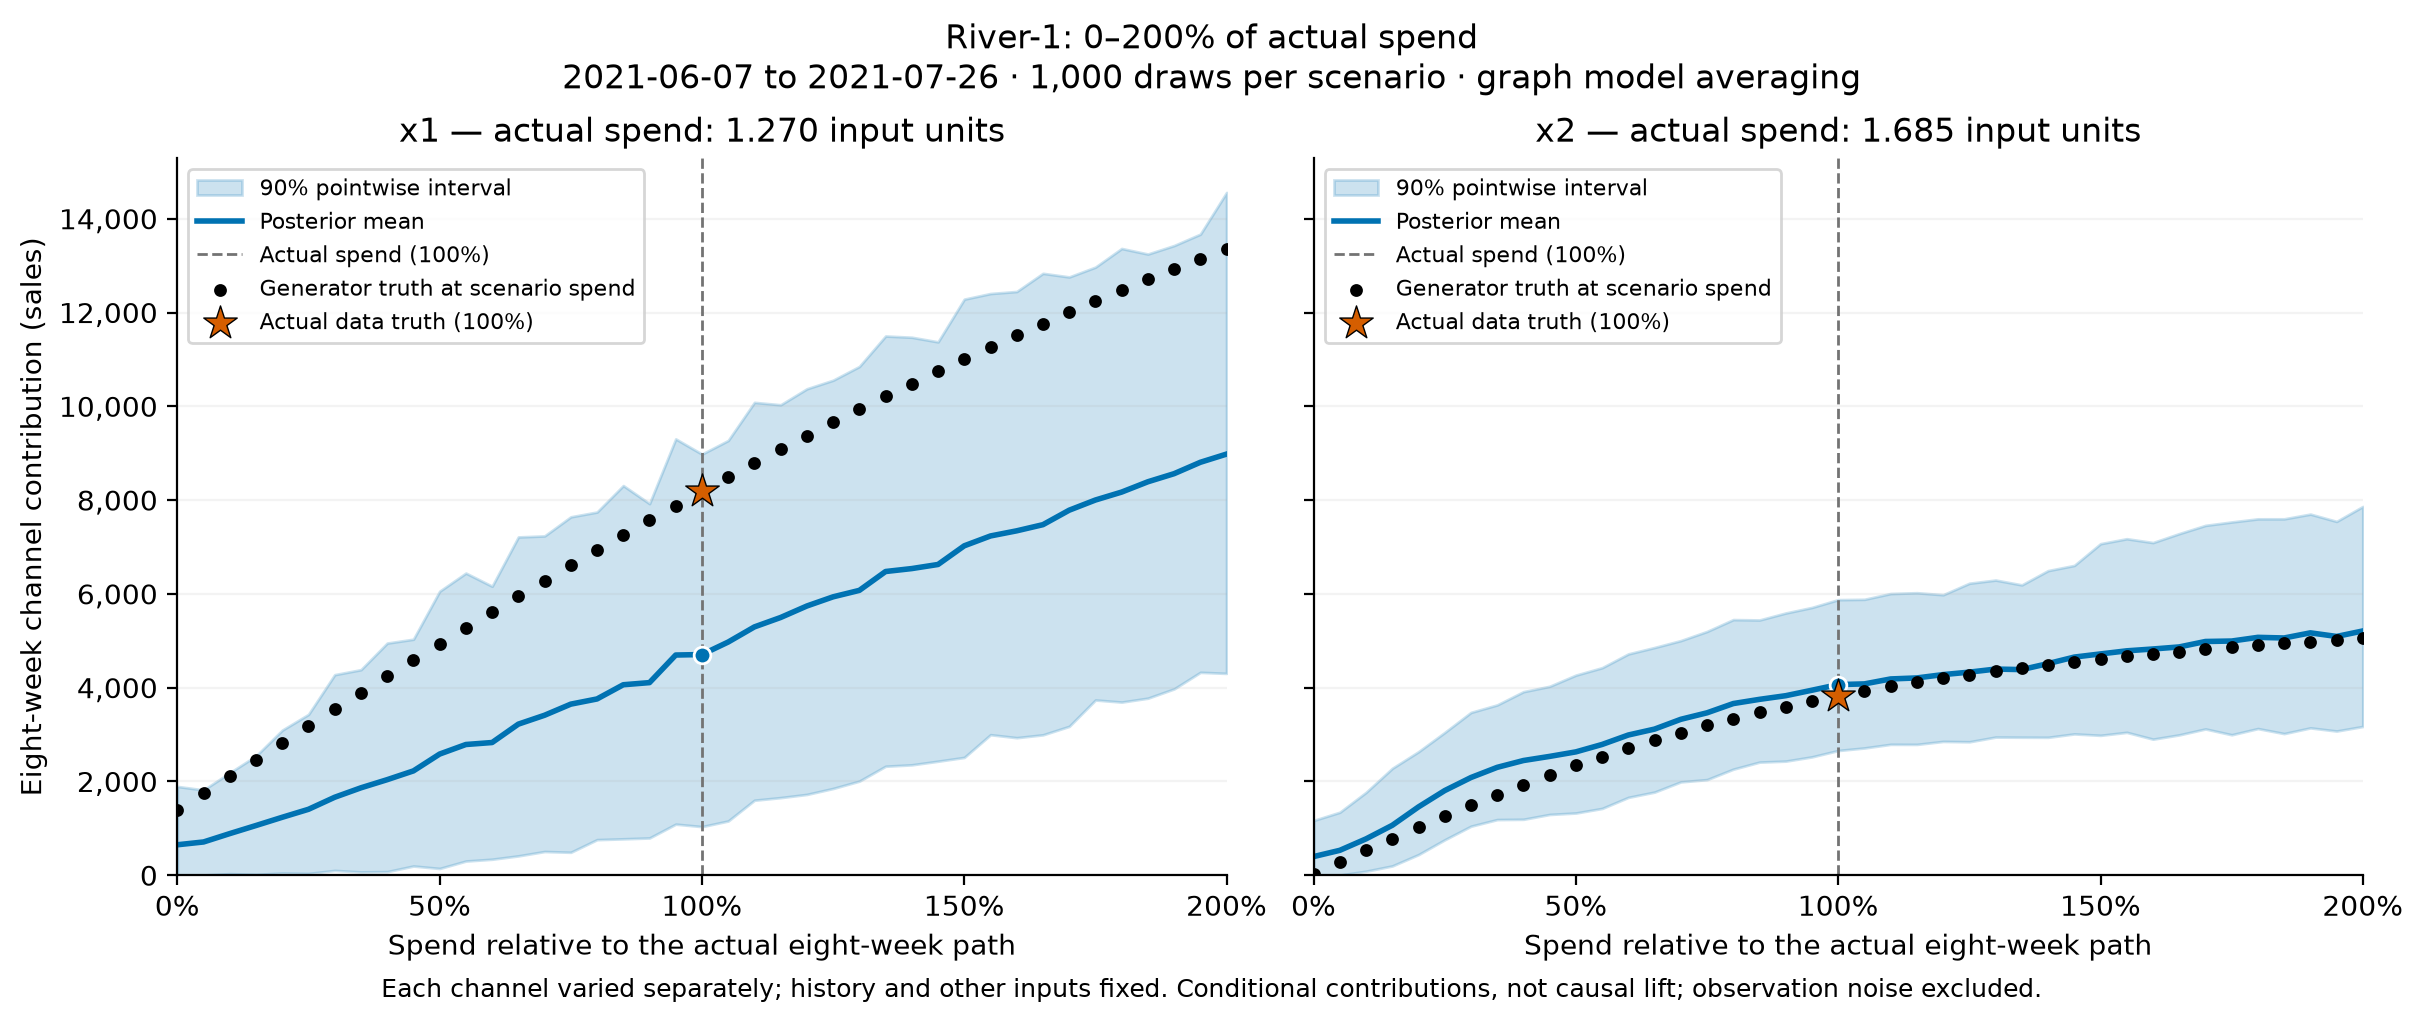

In [18]:
spend_percentages = 100 * spend_multipliers
actual_index = np.flatnonzero(spend_multipliers == 1.0).item()
sweep_fig, sweep_axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
for channel_index, (ax, name) in enumerate(zip(sweep_axes, names["channel_names"], strict=True)):
    draws = sweep_draws[name]
    mean = draws.mean(axis=1)
    low, high = np.quantile(draws, [0.05, 0.95], axis=1)
    ax.fill_between(
        spend_percentages,
        low,
        high,
        color=COLORS["channel"],
        alpha=0.2,
        label="90% pointwise interval",
    )
    ax.plot(
        spend_percentages,
        mean,
        color=COLORS["channel"],
        linewidth=2,
        label="Posterior mean",
    )
    ax.axvline(100, color="0.45", linestyle="--", linewidth=1, label="Actual spend (100%)")
    ax.scatter([100], [mean[actual_index]], color=COLORS["channel"], edgecolor="white", zorder=3)
    ax.scatter(
        spend_percentages,
        sweep_truth[name],
        color="black",
        s=13,
        zorder=4,
        label="Generator truth at scenario spend",
    )
    ax.scatter(
        [100],
        [channel_truth[sweep_window, channel_index].sum()],
        marker="*",
        color=COLORS["latent"],
        edgecolor="black",
        linewidth=0.5,
        s=160,
        zorder=5,
        label="Actual data truth (100%)",
    )
    ax.set(
        title=f"{name} — actual spend: {actual_spend_totals[channel_index]:.3f} input units",
        xlabel="Spend relative to the actual eight-week path",
        xlim=(0, 200),
        ylim=(0, None),
    )
    ax.set_xticks([0, 50, 100, 150, 200], ["0%", "50%", "100%", "150%", "200%"])
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.legend(fontsize=8, loc="upper left")
sweep_axes[0].set_ylabel("Eight-week channel contribution (sales)")
sweep_fig.suptitle(
    f"River-1: 0–200% of actual spend\n"
    f"{dates[CONTEXT]} to {dates[sweep_stop - 1]} · "
    f"{SWEEP_SAMPLES:,} draws per scenario · graph model averaging"
)
sweep_fig.supxlabel(
    "Each channel varied separately; history and other inputs fixed. "
    "Conditional contributions, not causal lift; observation noise excluded.",
    fontsize=9,
);

## 10. Inspect the discovered graphs

Reuse the existing `query` draws: none of the plots below reruns inference. The graph nodes
use the configured names `channel:x1`, `channel:x2`, `control:event_1` and `control:event_2`,
plus the model's active latent nodes and the target node `outcome`. Padded controls are omitted.

The labels **Graph 0**, **Graph 1**, and so on are zero-based **ranks**, not permanent graph IDs:
rank 0 has the largest draw count; ties use the ascending binary edge vector. Ranks can change
after a new inference call. Frequencies are empirical draw frequencies, not goodness-of-fit
scores, effect strengths or evidence of causal identification.

### Average graph

The Average combines the marginal edge frequencies of all sampled graphs. Numeric arrow
labels show frequencies, not effect sizes. Diagrams use Graphviz's unmodified default
layout and rendering through its `dot` executable. Install Graphviz first, for example
with `brew install graphviz` on macOS or `sudo apt-get install graphviz` on Ubuntu.
Writing DOT source does not require Graphviz.

The Average may combine edges never sampled together and may contain cycles; it is not
necessarily one complete graph that the model sampled.

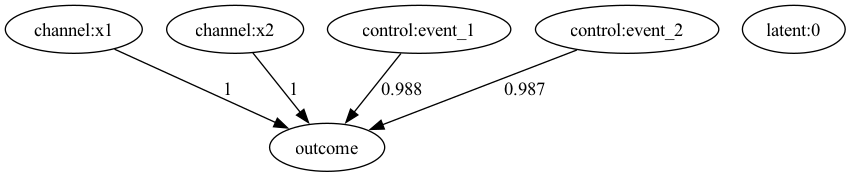

In [19]:
query.plot.dag()

### List graph ranks and inspect one topology

Build a table from the existing diagnostic evidence, using the same zero-based ordering
as the plots. `frequency` is a fraction from 0 to 1. `edge_count` counts the edges in that
complete graph, not the number of nonzero-frequency edges in the Average.

In [20]:
import pandas as pd
from IPython.display import display

graph_evidence = query_diagnostics.summary["arrays"]["graphs"]
graph_records = sorted(
    graph_evidence["complete_graphs"], key=lambda record: (-record["count"], record["graph"])
)
graph_catalog = pd.DataFrame(
    [
        {
            "graph_rank": rank,
            "draw_count": record["count"],
            "frequency": record["frequency"],
            "edge_count": sum(record["graph"]),
        }
        for rank, record in enumerate(graph_records)
    ]
).set_index("graph_rank")
graph_catalog

,draw_count,frequency,edge_count
graph_rank,,,
0,976,0.976,4
1,12,0.012,3
2,11,0.011,3
3,1,0.001,2


Change `selected_graph_rank` to any rank in the table. The connection table and diagram both
use that graph's exact binary edge vector; absent edges are not drawn. For an empty topology,
the connection table has no rows.

Graph 0: 976 draws; frequency 97.600%


,source,target
0,channel:x1,outcome
1,channel:x2,outcome
2,control:event_1,outcome
3,control:event_2,outcome


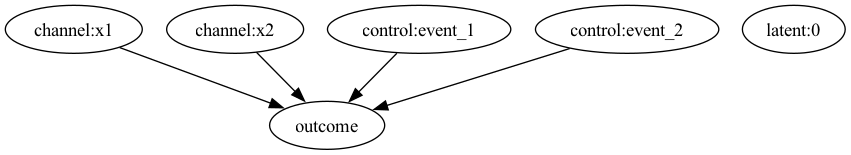

In [21]:
selected_graph_rank = 0
selected_graph = graph_records[selected_graph_rank]
selected_connections = [
    {"source": edge["endpoints"][0], "target": edge["endpoints"][1]}
    for edge, present in zip(graph_evidence["edges"], selected_graph["graph"], strict=True)
    if present
]
print(
    f"Graph {selected_graph_rank}: {selected_graph['count']} draws; "
    f"frequency {selected_graph['frequency']:.3%}"
)
display(pd.DataFrame(selected_connections, columns=["source", "target"]))
query.plot.dag(graph=selected_graph_rank)

### Plot several ranks, or all of them

Display the first three graphs to keep notebook output manageable. Set
`ranks_to_plot = list(graph_catalog.index)` to plot every discovered graph instead.
The printed captions identify each rank, draw count and frequency; the diagrams themselves
use Graphviz's defaults without custom styling.

Graph 0: 976 draws; frequency 97.600%


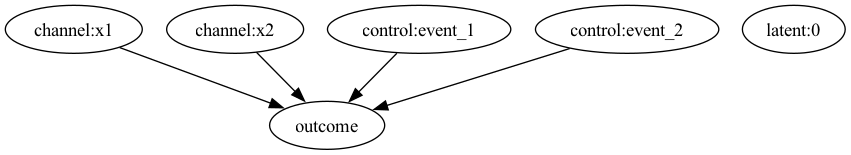

Graph 1: 12 draws; frequency 1.200%


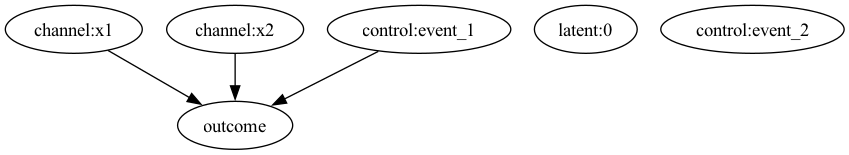

Graph 2: 11 draws; frequency 1.100%


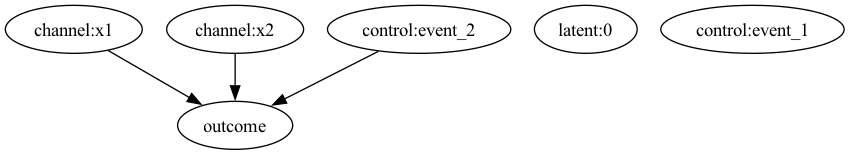

In [22]:
ranks_to_plot = list(graph_catalog.index[:3])
for graph_rank in ranks_to_plot:
    record = graph_records[int(graph_rank)]
    print(f"Graph {graph_rank}: {record['count']} draws; frequency {record['frequency']:.3%}")
    display(query.plot.dag(graph=int(graph_rank)))

### Export SVG and Graphviz DOT

Save the selected SVG and DOT source for both the Average and selected graph in the
temporary workspace. `query.plot.dot()` exports the Average; pass
`graph=selected_graph_rank` for an individual topology. No Graphviz installation is needed
to write DOT. Print the selected source below to inspect its named nodes and arrows.

Change `graph_export_dir` to a location you want to keep before running the final cleanup
cell. Exports contain graph topology, column labels and frequencies: review them before
sharing. They do not contain observation or contribution draws.

In [23]:
graph_export_dir = Path(workspace.name) / "graphs"
graph_export_dir.mkdir(exist_ok=True)
query.plot.dag(graph=selected_graph_rank).savefig(
    graph_export_dir / f"graph-{selected_graph_rank}.svg"
)
average_dot = query.plot.dot()
selected_dot = query.plot.dot(graph=selected_graph_rank)
(graph_export_dir / "graph-average.dot").write_text(average_dot, encoding="utf-8", newline="\n")
(graph_export_dir / f"graph-{selected_graph_rank}.dot").write_text(
    selected_dot, encoding="utf-8", newline="\n"
)
print("Saved the selected SVG and average/selected DOT in graph_export_dir.")
print(selected_dot)

Saved the selected SVG and average/selected DOT in graph_export_dir.
// Complete graph rank 0
// Prediction-only routing topology; supplied graph truth is not exported.
// Average shows marginal edge draw frequencies, not one complete sampled graph.
// Complete graph ranks show binary edges, ordered by count then binary vector.
// Frequencies are empirical router-draw frequencies, not fit or causal scores.
// MAP/fixed modes describe selected/supplied hypotheses, not posterior mass.
digraph {
  n0 [label="channel:x1"];
  n1 [label="outcome"];
  n2 [label="channel:x2"];
  n3 [label="latent:0"];
  n4 [label="control:event_1"];
  n5 [label="control:event_2"];
  n0 -> n1;
  n2 -> n1;
  n4 -> n1;
  n5 -> n1;
}



Optionally export **every** discovered graph:

```python
for graph_rank in graph_catalog.index:
    query.plot.dag(graph=int(graph_rank)).savefig(
        graph_export_dir / f"graph-{graph_rank}.svg"
    )
    (graph_export_dir / f"graph-{graph_rank}.dot").write_text(
        query.plot.dot(graph=int(graph_rank)), encoding="utf-8", newline="\n"
    )
```

The SVG export above is rendered by Graphviz's native engine, with its defaults unchanged.
To render a saved DOT file directly, run
`dot -Tsvg graph-0.dot -o graph-0-native.svg` in the export directory.

This can create many files; it is opt-in rather than part of Run All. All plots use the original
query draw bank, without resampling. MAP/fixed results contain only the selected/supplied
hypothesis, not the pre-selection graph distribution.


## 11. Recap

- **No fit.** River-1 decomposed the series with one call per window, 1,000 posterior draws each,
  and no model fitted to this dataset. It saw the sales of the 166 context weeks only.
- **Media split.** In the context, the x1 share of media contribution is 0.77 against a true 0.79.
  Both channel totals are inside their 90% intervals but below the truth (x1 205,599 against
  261,603; x2 62,515 against 70,252).
- **Held-out sales.** In the 42 query weeks, whose sales it never saw, the model's weekly sales
  have a mean absolute error of 760 and 90% of the observed weeks fall inside its 90% interval. Its
  sales run below the observations in the second half of the query.
- **Query channels.** The x2 total is recovered (12,833 against 13,690). x1 is underestimated: its
  truth (51,407) is above the 90% interval (21,417 to 47,060), and the x1 share drops to 0.72.
- **Weekly shape.** The trajectories follow the timing of each channel. x2's bursts land in the
  right weeks, but the carryover after each burst is shorter than the truth and a small
  contribution remains between bursts, where the truth is zero. x1 follows the shape of its truth
  and sits below it in most weeks, most clearly in the query.
- **Events.** Both one-week events are placed in their week, with a lift centred below the truth
  (1,500 and 2,500); part of event_1 spills into the following weeks.
- **Posteriors.** Every effect is a distribution, not a point estimate: the histograms show its
  spread and where the truth falls in it. On this dataset the truth sits in the upper part of every
  channel and event posterior: River-1 leans towards under-attribution here, with wide intervals
  that usually, but not always, contain the truth.

In [24]:
workspace.cleanup()  # Delete the downloaded bundle.